<a href="https://colab.research.google.com/github/roopeshscs24-maker/BIS-lab/blob/main/Genetic_Algo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Random seed for reproducibility
random.seed(42)
np.random.seed(42)

# Hospital staff
staff = ["Nurse_1", "Nurse_2", "Nurse_3", "Nurse_4",
         "Nurse_5", "Nurse_6"]

days = ["Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"]

shifts = ["Morning", "Evening", "Night"]

# Shift duration
shift_hours = 8

# Staff availability (1 = available, 0 = unavailable)
availability = {
    nurse: [1] * 21 for nurse in staff
}

# Example unavailability
availability["Nurse_1"][2] = 0
availability["Nurse_3"][7] = 0
availability["Nurse_5"][15] = 0

# Maximum shifts per nurse per week
max_shifts = 5

print("Hospital Staff Scheduling System")
print("Total staff:", len(staff))
print("Total days:", len(days))
print("Total shifts:", len(shifts))

Hospital Staff Scheduling System
Total staff: 6
Total days: 7
Total shifts: 3


In [15]:
POPULATION_SIZE = 100
GENERATIONS = 200
MUTATION_RATE = 0.10
CROSSOVER_RATE = 0.80
ELITE_SIZE = 10

# Objective weights
ALPHA = 1       # Workload imbalance
BETA = 1000     # Scheduling conflicts
GAMMA = 100     # Maximum shift violations

In [16]:
NUM_GENES = len(days) * len(shifts)

def create_chromosome():
    chromosome = []

    for i in range(NUM_GENES):
        available_nurses = [
            j for j, nurse in enumerate(staff)
            if availability[nurse][i] == 1
        ]

        chromosome.append(random.choice(available_nurses))

    return chromosome


def create_population():
    return [
        create_chromosome()
        for _ in range(POPULATION_SIZE)
    ]


population = create_population()

print("Initial population generated:", len(population))

Initial population generated: 100


In [17]:
def calculate_fitness(chromosome):

    workload = [0] * len(staff)
    total_shifts = [0] * len(staff)

    conflicts = 0
    max_violations = 0

    # Calculate workload and availability conflicts
    for i, nurse_index in enumerate(chromosome):

        nurse = staff[nurse_index]

        workload[nurse_index] += shift_hours
        total_shifts[nurse_index] += 1

        if availability[nurse][i] == 0:
            conflicts += 1

    # Check multiple shifts assigned on same day
    for day in range(len(days)):

        daily_assignments = chromosome[
            day * 3:(day + 1) * 3
        ]

        if len(set(daily_assignments)) < 3:
            conflicts += 1

    # Check night shift followed by morning shift
    for day in range(len(days) - 1):

        night_nurse = chromosome[day * 3 + 2]
        next_morning_nurse = chromosome[(day + 1) * 3]

        if night_nurse == next_morning_nurse:
            conflicts += 1

    # Maximum shifts constraint
    for count in total_shifts:
        if count > max_shifts:
            max_violations += count - max_shifts

    # Workload imbalance
    average_workload = np.mean(workload)

    imbalance = sum(
        (hours - average_workload) ** 2
        for hours in workload
    )

    # Minimize total penalty
    cost = (
        ALPHA * imbalance +
        BETA * conflicts +
        GAMMA * max_violations
    )

    fitness = 1 / (1 + cost)

    return fitness

In [18]:
def selection(population):

    tournament = random.sample(population, 5)

    winner = max(
        tournament,
        key=calculate_fitness
    )

    return winner.copy()

In [19]:
def crossover(parent1, parent2):

    child1 = parent1.copy()
    child2 = parent2.copy()

    if random.random() < CROSSOVER_RATE:

        point = random.randint(1, NUM_GENES - 1)

        child1 = parent1[:point] + parent2[point:]
        child2 = parent2[:point] + parent1[point:]

    return child1, child2

In [20]:
def mutation(chromosome):

    chromosome = chromosome.copy()

    for i in range(NUM_GENES):

        if random.random() < MUTATION_RATE:

            available_nurses = [
                j for j, nurse in enumerate(staff)
                if availability[nurse][i] == 1
            ]

            chromosome[i] = random.choice(available_nurses)

    return chromosome

In [21]:
population = create_population()

best_fitness_history = []
best_solution = None

for generation in range(GENERATIONS):

    population.sort(
        key=calculate_fitness,
        reverse=True
    )

    current_best = population[0]

    if (best_solution is None or
        calculate_fitness(current_best) >
        calculate_fitness(best_solution)):

        best_solution = current_best.copy()

    best_fitness_history.append(
        calculate_fitness(best_solution)
    )

    # Elitism
    new_population = [
        chromosome.copy()
        for chromosome in population[:ELITE_SIZE]
    ]

    # Generate new population
    while len(new_population) < POPULATION_SIZE:

        parent1 = selection(population)
        parent2 = selection(population)

        child1, child2 = crossover(parent1, parent2)

        child1 = mutation(child1)
        child2 = mutation(child2)

        new_population.append(child1)

        if len(new_population) < POPULATION_SIZE:
            new_population.append(child2)

    population = new_population

    if generation % 20 == 0:
        print(
            f"Generation {generation}: "
            f"Best Fitness = {best_fitness_history[-1]:.6f}"
        )

print("\nGenetic Algorithm Completed!")
print("Best Fitness:", calculate_fitness(best_solution))

Generation 0: Best Fitness = 0.000675
Generation 20: Best Fitness = 0.010309
Generation 40: Best Fitness = 0.010309
Generation 60: Best Fitness = 0.010309
Generation 80: Best Fitness = 0.010309
Generation 100: Best Fitness = 0.010309
Generation 120: Best Fitness = 0.010309
Generation 140: Best Fitness = 0.010309
Generation 160: Best Fitness = 0.010309
Generation 180: Best Fitness = 0.010309

Genetic Algorithm Completed!
Best Fitness: 0.010309278350515464


In [22]:
schedule = []

for day in range(len(days)):

    row = {"Day": days[day]}

    for shift in range(3):

        gene_index = day * 3 + shift

        nurse_index = best_solution[gene_index]

        row[shifts[shift]] = staff[nurse_index]

    schedule.append(row)

df = pd.DataFrame(schedule)

print("\n========== OPTIMIZED HOSPITAL STAFF SCHEDULE ==========\n")

display(df)


========== OPTIMIZED HOSPITAL STAFF SCHEDULE ==========



,Day,Morning,Evening,Night
0,Monday,Nurse_4,Nurse_5,Nurse_3
1,Tuesday,Nurse_6,Nurse_1,Nurse_3
2,Wednesday,Nurse_1,Nurse_2,Nurse_6
3,Thursday,Nurse_3,Nurse_2,Nurse_4
4,Friday,Nurse_5,Nurse_2,Nurse_4
5,Saturday,Nurse_6,Nurse_5,Nurse_1
6,Sunday,Nurse_5,Nurse_1,Nurse_3


In [23]:
workload = {nurse: 0 for nurse in staff}
shift_count = {nurse: 0 for nurse in staff}

for nurse_index in best_solution:

    nurse = staff[nurse_index]

    workload[nurse] += shift_hours
    shift_count[nurse] += 1

workload_df = pd.DataFrame({
    "Staff": staff,
    "Total Shifts": [shift_count[n] for n in staff],
    "Working Hours": [workload[n] for n in staff]
})

print("\n========== WORKLOAD DISTRIBUTION ==========\n")

display(workload_df)

print("Average working hours:",
      np.mean(list(workload.values())))

print("Workload standard deviation:",
      round(np.std(list(workload.values())), 2))


========== WORKLOAD DISTRIBUTION ==========



,Staff,Total Shifts,Working Hours
0,Nurse_1,4,32
1,Nurse_2,3,24
2,Nurse_3,4,32
3,Nurse_4,3,24
4,Nurse_5,4,32
5,Nurse_6,3,24


Average working hours: 28.0
Workload standard deviation: 4.0


In [24]:
def detect_conflicts(chromosome):

    conflicts = []

    # Availability conflicts
    for i, nurse_index in enumerate(chromosome):

        nurse = staff[nurse_index]

        if availability[nurse][i] == 0:
            conflicts.append(
                f"{nurse} unavailable on "
                f"{days[i // 3]} - {shifts[i % 3]}"
            )

    # Same nurse assigned multiple shifts per day
    for day in range(len(days)):

        assignments = chromosome[day * 3:(day + 1) * 3]

        if len(set(assignments)) < 3:
            conflicts.append(
                f"Duplicate assignment on {days[day]}"
            )

    # Night to next-day morning conflicts
    for day in range(len(days) - 1):

        night = chromosome[day * 3 + 2]
        morning = chromosome[(day + 1) * 3]

        if night == morning:
            conflicts.append(
                f"Insufficient rest: {staff[night]} "
                f"on {days[day]} Night and "
                f"{days[day + 1]} Morning"
            )

    # Maximum shifts
    for nurse in staff:

        if shift_count[nurse] > max_shifts:
            conflicts.append(
                f"{nurse} exceeds maximum shifts"
            )

    return conflicts


conflicts = detect_conflicts(best_solution)

print("\n========== SCHEDULING CONFLICT REPORT ==========\n")

if len(conflicts) == 0:
    print("No scheduling conflicts detected!")
else:
    for conflict in conflicts:
        print("WARNING:", conflict)

print("\nTotal conflicts:", len(conflicts))


========== SCHEDULING CONFLICT REPORT ==========

No scheduling conflicts detected!

Total conflicts: 0


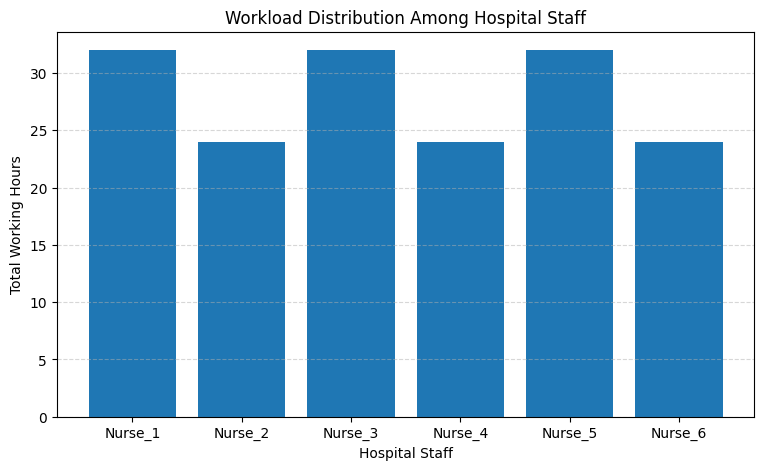

In [25]:
plt.figure(figsize=(9, 5))

plt.bar(
    staff,
    [workload[n] for n in staff]
)

plt.xlabel("Hospital Staff")
plt.ylabel("Total Working Hours")
plt.title("Workload Distribution Among Hospital Staff")

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

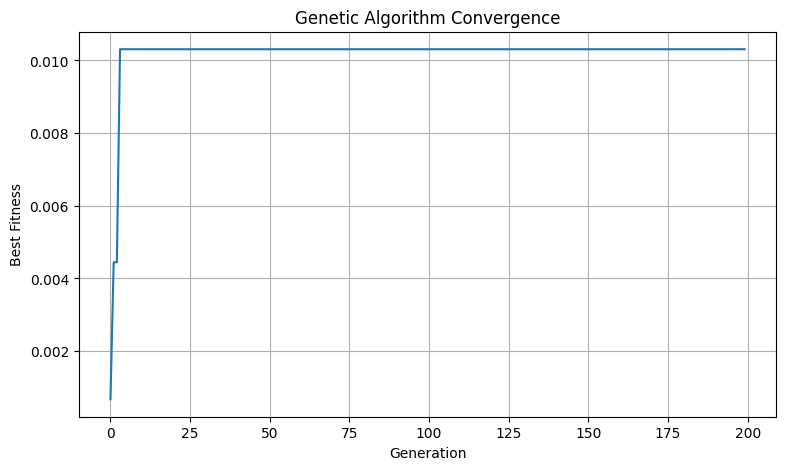

In [26]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(GENERATIONS),
    best_fitness_history
)

plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.title("Genetic Algorithm Convergence")

plt.grid(True)

plt.show()